In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [28]:
df = pd.read_csv("housing.csv")
df.head()

,Unnamed: 0,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [29]:
df.shape # (rows, columns)

(20640, 10)

In [30]:
df = df.drop_duplicates()
df = df.dropna()
df.shape

(20640, 10)

In [31]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,20640.0,10319.500000,5958.399114,0.000000,5159.750000,10319.500000,15479.250000,20639.000000
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


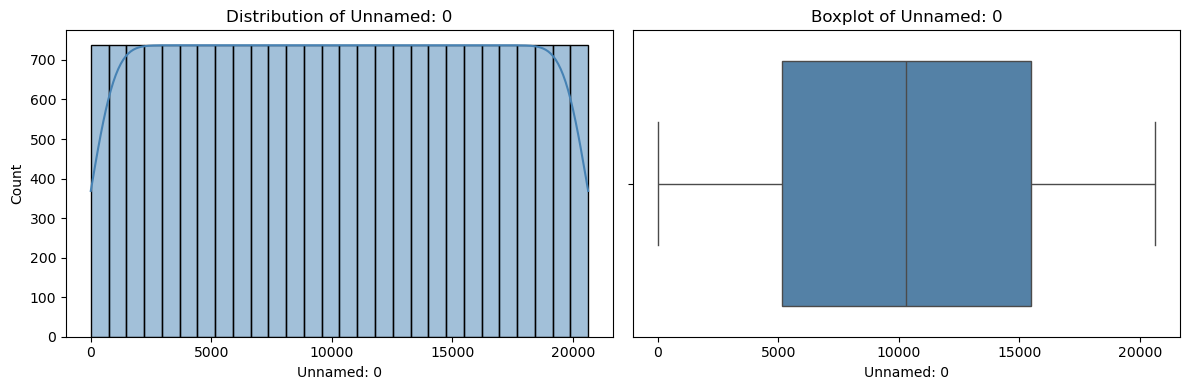

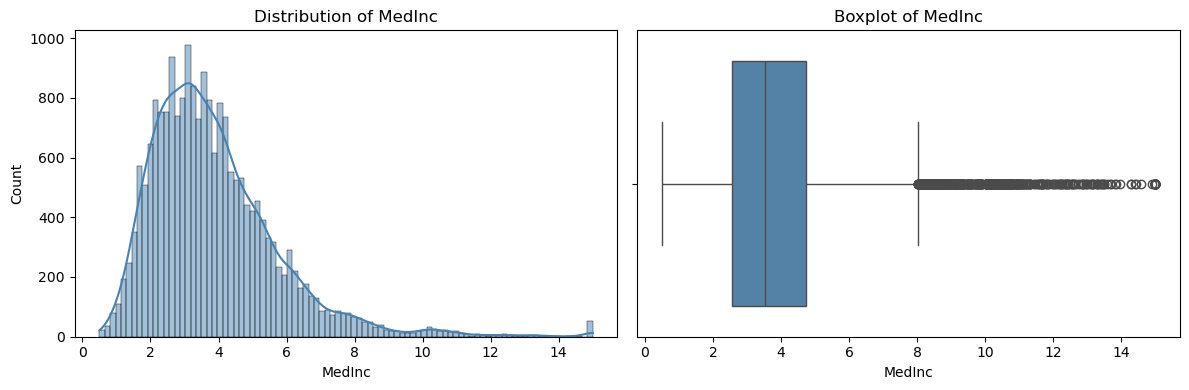

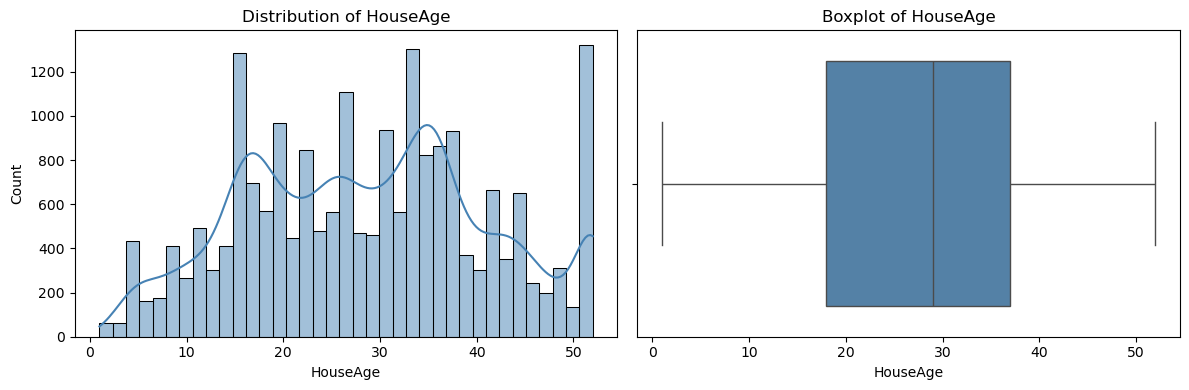

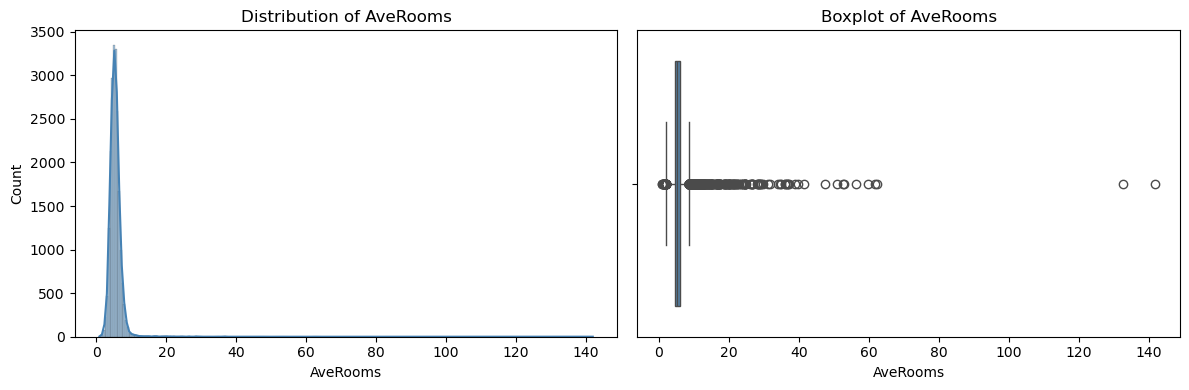

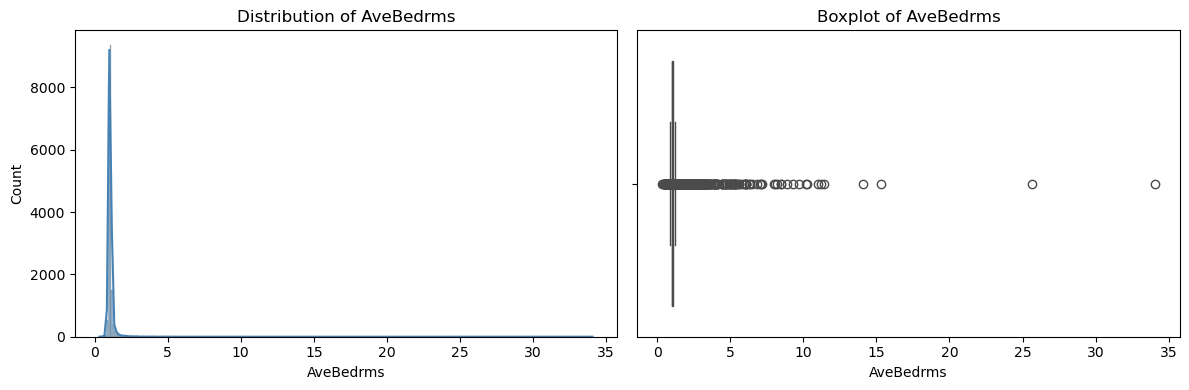

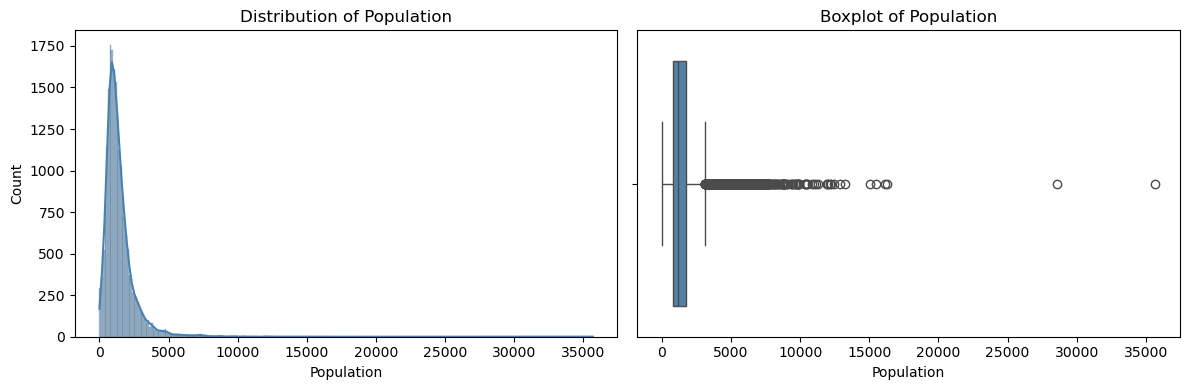

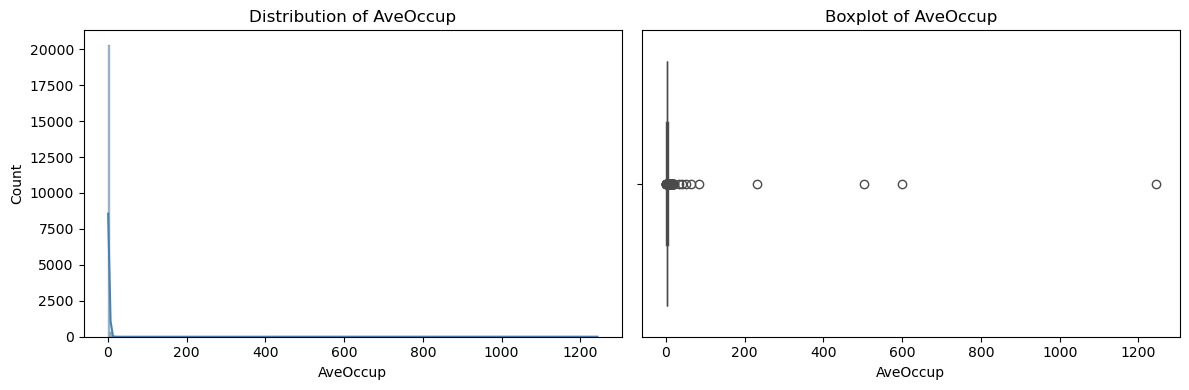

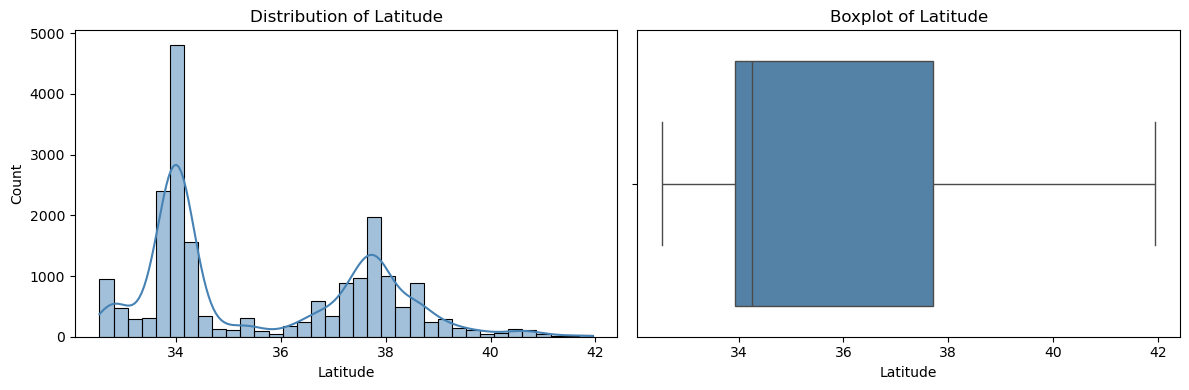

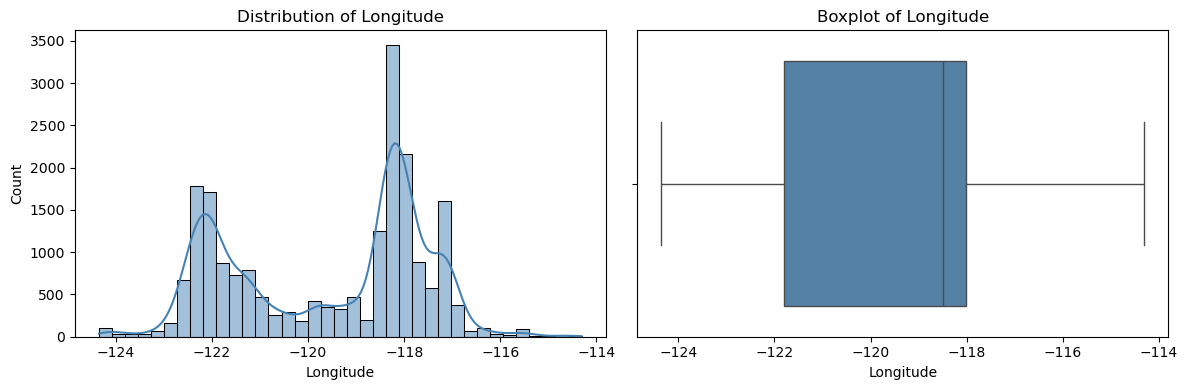

In [14]:
numerical_cols = df.columns.drop('MedHouseVal')

for col in numerical_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(df[col], kde=True, ax=axes[0], color="steelblue")
    sns.boxplot(x=df[col], ax=axes[1], color="steelblue")
    axes[0].set_title(f"Distribution of {col}")
    axes[1].set_title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

In [32]:

X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal'].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

input_shape = (X_train.shape[1],)

In [33]:
model = keras.Sequential(
    [
        layers.Input(shape=input_shape),
        # Hidden Layer 1
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        # Hidden Layer 2
        layers.Dense(64, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        # Hidden Layer 3
        layers.Dense(32, activation="relu"),
        # Output Layer: 1 linear neuron for price prediction
        layers.Dense(1),
    ]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,417 (48.50 KB)

 Trainable params: 12,033 (47.00 KB)

 Non-trainable params: 384 (1.50 KB)

In [34]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mean_squared_error",  # MSE penalizes larger estimation mistakes
    metrics=["mae"],  # Track MAE in dollar units
)

In [35]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
)

In [36]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    batch_size=128,
    epochs=100,
    callbacks=[early_stopping],
    verbose=1,
)

Epoch 1/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.1310 - mae: 0.7749 - val_loss: 2.2316 - val_mae: 1.1489
Epoch 2/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6179 - mae: 0.5851 - val_loss: 1.0306 - val_mae: 0.7054
Epoch 3/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5408 - mae: 0.5406 - val_loss: 0.6734 - val_mae: 0.5583
Epoch 4/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4920 - mae: 0.5151 - val_loss: 0.4702 - val_mae: 0.4661
Epoch 5/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4626 - mae: 0.4988 - val_loss: 0.4676 - val_mae: 0.4609
Epoch 6/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4250 - mae: 0.4781 - val_loss: 0.4307 - val_mae: 0.4392
Epoch 7/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4172 - mae: 0.4671 - val_loss: 0.4150 - val_mae: 0.4395
Epoch 8/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3987 - mae: 0.4537 - val_loss: 0.3676 - val_mae: 0.4247
Epoch 9/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 918us/step

Test MAE : 0.3522 ($100k units) -> ~$35,216
Test MSE : 0.2795
R² Score : 0.7867 (78.7% variance explained)

--- Sample Predictions ---
Actual: $47,700 | Pred: $61,990 | Diff: $14,290
Actual: $45,800 | Pred: $88,890 | Diff: $43,090
Actual: $500,001 | Pred: $448,024 | Diff: $51,977
Actual: $218,600 | Pred: $255,365 | Diff: $36,765
Actual: $278,000 | Pred: $257,785 | Diff: $20,215


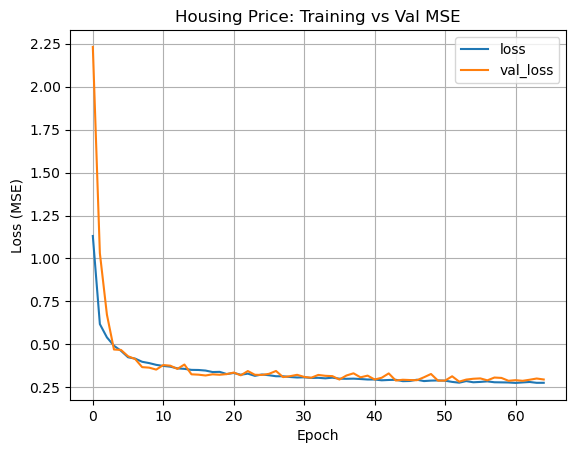

In [37]:
test_loss, test_mae = model.evaluate(X_test, y_test, verbose=0)
preds = model.predict(X_test).flatten()
# R² Score (percentage of price variance explained)
r2 = r2_score(y_test, preds)
print("\n" + "=" * 40)
print(f"Test MAE : {test_mae:.4f} ($100k units) -> ~${test_mae * 100_000:,.0f}")
print(f"Test MSE : {test_loss:.4f}")
print(f"R² Score : {r2:.4f} ({r2 * 100:.1f}% variance explained)")
print("=" * 40)
# Sample Predictions
print("\n--- Sample Predictions ---")
for actual, pred in zip(y_test[:5], preds[:5]):
  actual_dollar = actual * 100_000
  pred_dollar = pred * 100_000
  diff = abs(actual_dollar - pred_dollar)
  print(
      f"Actual: ${actual_dollar:,.0f} | Pred: ${pred_dollar:,.0f} | Diff:"
      f" ${diff:,.0f}"
  )
# ==============================================================================
# 7. Plot Loss Curves
# ==============================================================================
history_df = pd.DataFrame(history.history)
history_df[["loss", "val_loss"]].plot(title="Housing Price: Training vs Val MSE")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.grid(True)
plt.show()